## BRP Bicing - Optimización de Rutas de Redistribución

Objetivo: dado el modelo de predicción de demanda seleccionado (XGBoost, MAE test = 0.061, mejor que el LSTM final y que el baseline de persistencia; ver notebook LSTM), planificar las rutas de los camiones de redistribución para minimizar el desequilibrio de las estaciones. En este notebook la demanda se aproxima con promedios históricos por franja horaria; la integración del modelo XGBoost queda como extensión futura.

Estructura del notebook:
1. Carga de datos y configuración
2. EDA — último mes disponible (septiembre 2025)
3. Formulación y resolución del modelo de optimización (VRP/greedy)
4. Evaluación y visualización de rutas

## 1. Carga de librerías y configuración

In [31]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap, MarkerCluster

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)

ROOT      = Path('../')
PROC_DIR  = ROOT / 'data' / 'processed'

# Umbral de desequilibrio: estación vacía / llena
THR_EMPTY = 0.10
THR_FULL  = 0.90

# Mes analizado
LAST_MONTH_START = pd.Timestamp('2025-09-01')

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


### 2.1 Carga y preprocesamiento

In [32]:
stations = pd.read_parquet(PROC_DIR / 'bicing_stations.parquet')
hourly   = pd.read_parquet(PROC_DIR / 'bicing_hourly.parquet')

# Filtrar último mes
last = hourly[hourly['hora'] >= LAST_MONTH_START].copy()
last = last.merge(
    stations[['station_id', 'capacity', 'lat', 'lon', 'name', 'altitude']],
    on='station_id', how='left'
)

cap = last['capacity'].replace(0, np.nan)
last['occupancy_rate'] = (last['num_bikes_available'] / cap).clip(0, 1)
last['is_empty'] = last['occupancy_rate'] < THR_EMPTY
last['is_full']  = last['occupancy_rate'] > THR_FULL

print(f"Registros: {len(last):,}")
print(f"Estaciones: {last['station_id'].nunique()}")
print(f"Periodo:   {last['hora'].min().date()} → {last['hora'].max().date()}")
print(f"% horas vacía (<{THR_EMPTY:.0%}): {last['is_empty'].mean():.2%}")
print(f"% horas llena (>{THR_FULL:.0%}): {last['is_full'].mean():.2%}")

Registros: 378,401
Estaciones: 546
Periodo:   2025-09-01 → 2025-09-30
% horas vacía (<10%): 28.66%
% horas llena (>90%): 2.14%


### 2.2 Métrica de desequilibrio por estación

In [33]:
sta = last.groupby('station_id').agg(
    occ_mean  = ('occupancy_rate', 'mean'),
    occ_std   = ('occupancy_rate', 'std'),
    pct_empty = ('is_empty', 'mean'),
    pct_full  = ('is_full',  'mean'),
    capacity  = ('capacity', 'first'),
    lat       = ('lat',      'first'),
    lon       = ('lon',      'first'),
    name      = ('name',     'first'),
    altitude  = ('altitude', 'first'),
).reset_index()

sta['imbalance'] = sta['pct_empty'] + sta['pct_full']

print('Top 10 estaciones más desequilibradas:')
display(
    sta.sort_values('imbalance', ascending=False)
       .head(10)[['station_id','name','occ_mean','pct_empty','pct_full','imbalance','capacity']]
       .style.format({'occ_mean':'{:.2%}','pct_empty':'{:.2%}','pct_full':'{:.2%}','imbalance':'{:.2%}'})
       .background_gradient(subset=['imbalance'], cmap='Reds')
)

Top 10 estaciones más desequilibradas:


,station_id,name,occ_mean,pct_empty,pct_full,imbalance,capacity
518,553,"VIA AUGUSTA, 68",5.02%,87.63%,0.00%,87.63%,32
476,488,"AV. CAN MARCET, 36",5.34%,84.94%,0.00%,84.94%,27
501,513,"VIA AUGUSTA, 317",5.81%,84.94%,0.00%,84.94%,28
521,561,"C/ MANILA, 53",5.47%,83.07%,0.00%,83.07%,24
527,568,"C/ ROMÁN MACAYA, 8",5.61%,81.06%,0.00%,81.06%,24
329,338,"AV. JOSEP VICENÇ FOIX, 63",6.00%,80.49%,0.00%,80.49%,36
497,509,"C/ TORRENT DE L'OLLA, 11",7.21%,79.53%,0.00%,79.53%,32
522,563,"C/ ENTENÇA, 301",6.75%,78.62%,0.00%,78.62%,24
328,337,"C/ CARME KARR, 12-14",6.78%,78.48%,0.00%,78.48%,23
422,433,"C/ J. MAYNARD KEYNES, 2|AV. DGNAL.",11.98%,76.98%,1.44%,78.42%,53


### 2.3 Distribución de ocupación

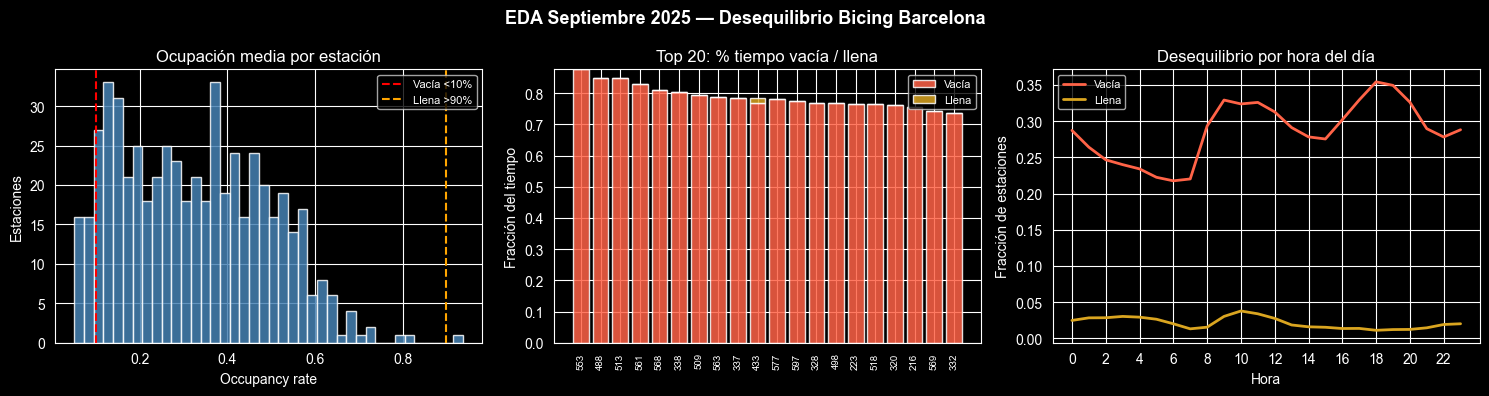

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histograma de ocupación media por estación
ax = axes[0]
ax.hist(sta['occ_mean'], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
ax.axvline(THR_EMPTY, color='red',    linestyle='--', linewidth=1.5, label=f'Vacía <{THR_EMPTY:.0%}')
ax.axvline(THR_FULL,  color='orange', linestyle='--', linewidth=1.5, label=f'Llena >{THR_FULL:.0%}')
ax.set_title('Ocupación media por estación')
ax.set_xlabel('Occupancy rate')
ax.set_ylabel('Estaciones')
ax.legend(fontsize=8)

# % tiempo vacía vs. llena (top 20 desequilibradas)
top20 = sta.sort_values('imbalance', ascending=False).head(20)
ax = axes[1]
x = np.arange(len(top20))
ax.bar(x, top20['pct_empty'], label='Vacía', color='tomato',    alpha=0.85)
ax.bar(x, top20['pct_full'],  label='Llena', color='goldenrod', alpha=0.85, bottom=top20['pct_empty'].values)
ax.set_xticks(x)
ax.set_xticklabels(top20['station_id'], rotation=90, fontsize=7)
ax.set_title('Top 20: % tiempo vacía / llena')
ax.set_ylabel('Fracción del tiempo')
ax.legend(fontsize=8)

# Desequilibrio por hora del día
ax = axes[2]
last['hour'] = last['hora'].dt.hour
imb_hour = last.groupby('hour').agg(
    empty=('is_empty','mean'), full=('is_full','mean')
)
ax.plot(imb_hour.index, imb_hour['empty'], label='Vacía', color='tomato',    linewidth=2)
ax.plot(imb_hour.index, imb_hour['full'],  label='Llena', color='goldenrod', linewidth=2)
ax.set_title('Desequilibrio por hora del día')
ax.set_xlabel('Hora')
ax.set_ylabel('Fracción de estaciones')
ax.legend(fontsize=8)
ax.set_xticks(range(0, 24, 2))

plt.suptitle('EDA Septiembre 2025 — Desequilibrio Bicing Barcelona', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.4 Desequilibrio por día de la semana

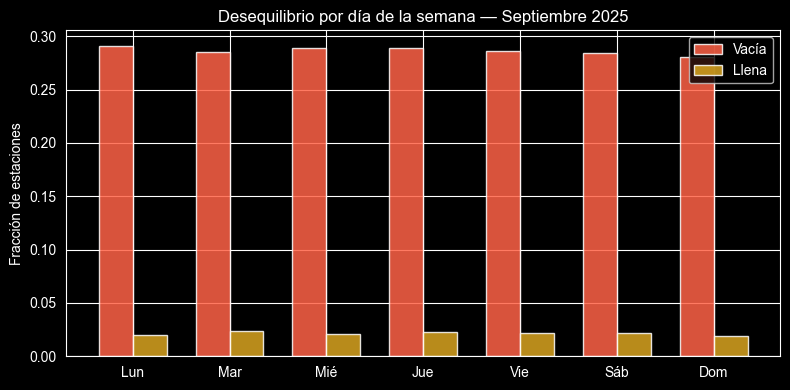

In [35]:
last['dow'] = last['hora'].dt.dayofweek
dow_labels  = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']

imb_dow = last.groupby('dow').agg(
    empty=('is_empty','mean'), full=('is_full','mean')
)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(7)
w = 0.35
ax.bar(x - w/2, imb_dow['empty'], w, label='Vacía', color='tomato',    alpha=0.85)
ax.bar(x + w/2, imb_dow['full'],  w, label='Llena', color='goldenrod', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(dow_labels)
ax.set_title('Desequilibrio por día de la semana — Septiembre 2025')
ax.set_ylabel('Fracción de estaciones')
ax.legend()
plt.tight_layout()
plt.show()

### 2.5 Mapa interactivo de estaciones

In [36]:
m = folium.Map(
    location=[41.3900, 2.1540],
    zoom_start=13,
    tiles='CartoDB positron'
)

def imb_color(imb):
    if imb > 0.7:   return 'red'
    elif imb > 0.4: return 'orange'
    elif imb > 0.2: return 'lightgreen'
    else:           return 'green'

for _, row in sta.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=max(4, row['capacity'] / 6),
        color=imb_color(row['imbalance']),
        fill=True,
        fill_opacity=0.7,
        tooltip=(
            f"<b>{row['name']}</b><br>"
            f"ID: {row['station_id']}<br>"
            f"Capacidad: {int(row['capacity'])}<br>"
            f"Occ. media: {row['occ_mean']:.1%}<br>"
            f"% vacía: {row['pct_empty']:.1%}<br>"
            f"% llena: {row['pct_full']:.1%}<br>"
            f"Desequilibrio: {row['imbalance']:.1%}"
        )
    ).add_to(m)

legend_html = '''
<div style="position:fixed; bottom:30px; left:30px; z-index:1000;
     background:white; padding:10px; border-radius:8px;
     border:1px solid #ccc; font-size:12px;">
  <b>Desequilibrio (% tiempo crítico)</b><br>
  <span style="color:red">●</span> &gt;70%<br>
  <span style="color:orange">●</span> 40–70%<br>
  <span style="color:lightgreen">●</span> 20–40%<br>
  <span style="color:green">●</span> &lt;20%
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

m

### 2.6 Heatmap temporal: ocupación por estación

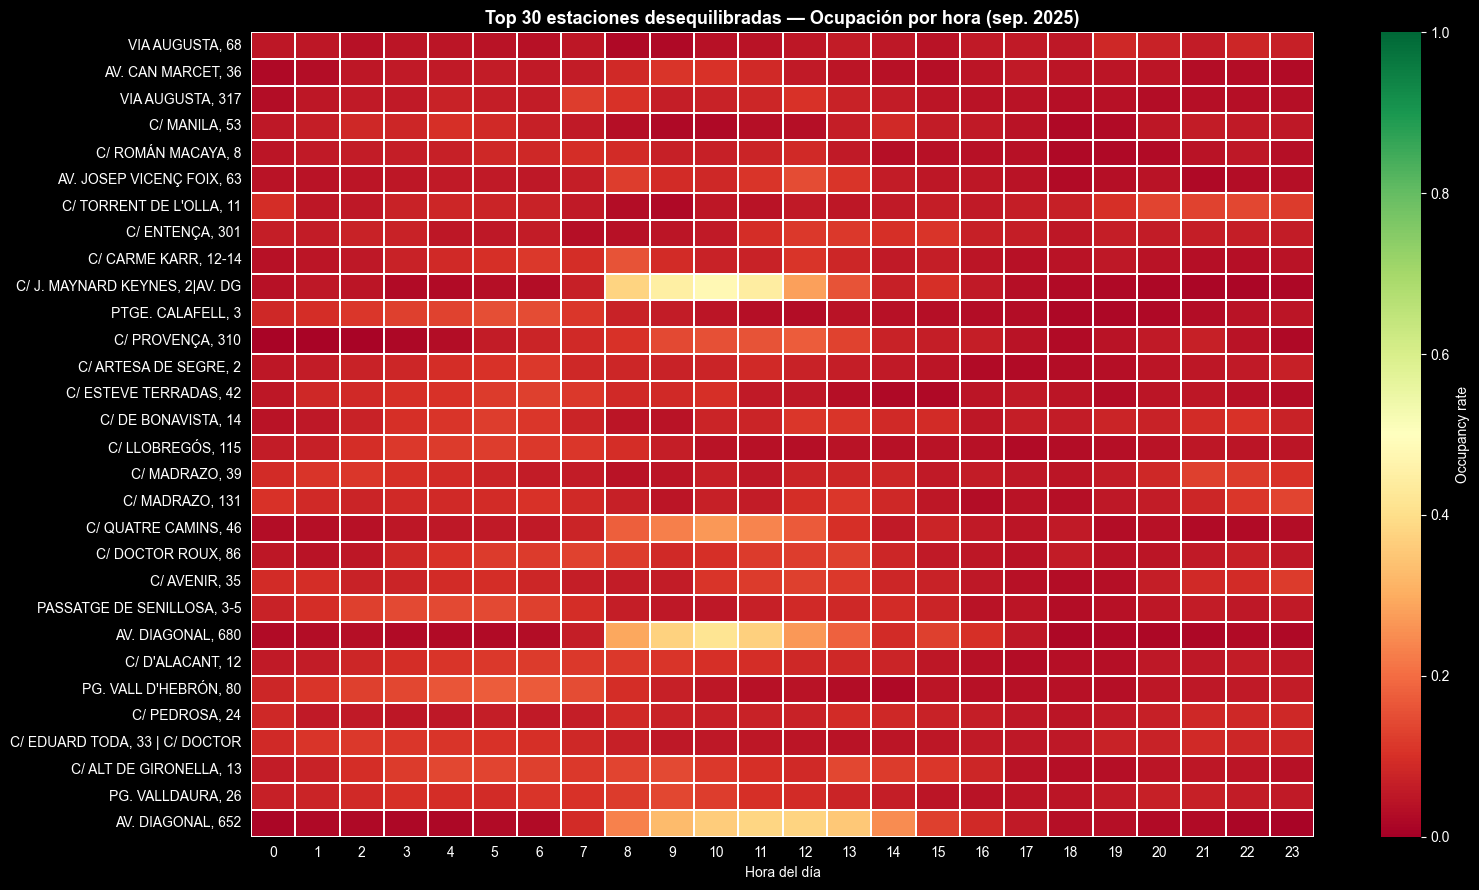

In [37]:
top30_ids = sta.sort_values('imbalance', ascending=False).head(30)['station_id'].tolist()

pivot = (
    last[last['station_id'].isin(top30_ids)]
    .groupby(['station_id', 'hour'])['occupancy_rate']
    .mean()
    .unstack('hour')
    .reindex(top30_ids)
)

top30_names = sta.set_index('station_id').loc[top30_ids, 'name'].str[:30]
pivot.index = top30_names

fig, ax = plt.subplots(figsize=(16, 9))
sns.heatmap(
    pivot, ax=ax,
    cmap='RdYlGn', vmin=0, vmax=1,
    linewidths=0.3, linecolor='white',
    cbar_kws={'label': 'Occupancy rate'}
)
ax.set_title('Top 30 estaciones desequilibradas — Ocupación por hora (sep. 2025)', fontsize=13, fontweight='bold')
ax.set_xlabel('Hora del día')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### 2.7 Resumen ejecutivo EDA

In [38]:
n_critical = (sta['imbalance'] > 0.4).sum()
n_ok       = (sta['imbalance'] < 0.2).sum()

print('=' * 55)
print('RESUMEN EDA — Septiembre 2025')
print('=' * 55)
print(f"Total estaciones analizadas  : {len(sta)}")
print(f"Estaciones críticas (>40%)   : {n_critical} ({n_critical/len(sta):.1%})")
print(f"Estaciones equilibradas (<20%): {n_ok} ({n_ok/len(sta):.1%})")
print(f"% global tiempo vacía        : {sta['pct_empty'].mean():.2%}")
print(f"% global tiempo llena        : {sta['pct_full'].mean():.2%}")
print(f"Peor estación (desequilibrio): {sta.loc[sta['imbalance'].idxmax(), 'name']}")
print(f"  → {sta['imbalance'].max():.2%} del tiempo en estado crítico")
print('=' * 55)
print()
print('→ Siguiente: modelo de optimización VRP (sección 3)')

RESUMEN EDA — Septiembre 2025
Total estaciones analizadas  : 546
Estaciones críticas (>40%)   : 187 (34.2%)
Estaciones equilibradas (<20%): 244 (44.7%)
% global tiempo vacía        : 28.62%
% global tiempo llena        : 2.23%
Peor estación (desequilibrio): VIA AUGUSTA, 68
  → 87.63% del tiempo en estado crítico

→ Siguiente: modelo de optimización VRP (sección 3)


## 3. Formulación y resolución del modelo de optimización (VRP)

El Bike Redistribution Problem (BRP) es una variante del Vehicle Routing Problem (VRP) donde una flota de camiones redistribuye bicicletas entre estaciones para minimizar el desequilibrio global.

Hipótesis del modelo:
- Escenario: martes a las 8 h (hora punta de máximo desequilibrio)
- Un depósito central de donde parten y regresan todos los camiones
- Objetivo de ocupación: 50 % de la capacidad por estación
- Algoritmo: heurística greedy nearest-neighbor con gestión de carga

### 3.1 Parámetros del modelo y escenario

In [39]:
# ── Parámetros de la flota ─────────────────────────────────────────────────
N_TRUCKS  = 5        # número de camiones
TRUCK_CAP = 30       # capacidad máxima de bicicletas por camión
MAX_STOPS = 20       # paradas máximas por ruta (sin contar depósito)

# Depósito: centro logístico aproximado de Bicing (Zona Franca / Meridiana)
DEPOT_LAT = 41.3680
DEPOT_LON = 2.1520
DEPOT_NAME = 'Depósito central'

# Objetivo de ocupación y umbral mínimo de intervención
TARGET_OCC = 0.50   # 50 % de la capacidad
MIN_BIKES  = 3      # déficit/superávit mínimo para considerar una estación

# Escenario: martes (dow=1) a las 8 h
SCENARIO_DOW  = 1
SCENARIO_HOUR = 8

# ── Snapshot del escenario ─────────────────────────────────────────────────
snap = (
    last[(last['dow'] == SCENARIO_DOW) & (last['hour'] == SCENARIO_HOUR)]
    .groupby('station_id')
    .agg(
        bikes_now = ('num_bikes_available', 'mean'),
        capacity  = ('capacity', 'first'),
        lat       = ('lat',      'first'),
        lon       = ('lon',      'first'),
        name      = ('name',     'first'),
    )
    .reset_index()
)

snap['target']  = (snap['capacity'] * TARGET_OCC).round()
snap['deficit'] = (snap['target'] - snap['bikes_now']).round().astype(int)

n_sinks   = (snap['deficit'] >  MIN_BIKES).sum()
n_sources = (snap['deficit'] < -MIN_BIKES).sum()

print(f"Escenario: {'Lun Mar Mié Jue Vie Sáb Dom'.split()[SCENARIO_DOW]} {SCENARIO_HOUR}:00 h")
print(f"Estaciones con déficit  (necesitan bicis): {n_sinks}")
print(f"Estaciones con superávit (tienen exceso) : {n_sources}")
print(f"Déficit medio : {snap[snap['deficit'] >  MIN_BIKES]['deficit'].mean():.1f} bicis")
print(f"Superávit medio: {snap[snap['deficit'] < -MIN_BIKES]['deficit'].abs().mean():.1f} bicis")


Escenario: Mar 8:00 h
Estaciones con déficit  (necesitan bicis): 361
Estaciones con superávit (tienen exceso) : 43
Déficit medio : 8.7 bicis
Superávit medio: 6.9 bicis


### 3.2 Función de distancia y utilidades

In [40]:
from math import radians, cos, sin, asin, sqrt

def haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos puntos geográficos (fórmula de Haversine)."""
    R = 6371.0
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat / 2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2)**2
    return 2 * R * asin(sqrt(a))

def nearest_station(pos_lat, pos_lon, candidates):
    """Devuelve el índice del DataFrame del candidato más cercano."""
    dists = candidates.apply(
        lambda r: haversine(pos_lat, pos_lon, r['lat'], r['lon']), axis=1
    )
    return dists.idxmin()

print('Función Haversine y utilidades cargadas.')
print(f"Distancia depósito → centro Barcelona: "
      f"{haversine(DEPOT_LAT, DEPOT_LON, 41.3851, 2.1734):.2f} km")


Función Haversine y utilidades cargadas.
Distancia depósito → centro Barcelona: 2.61 km


### 3.3 Algoritmo greedy nearest-neighbor (VRP)

Cada camión realiza el siguiente ciclo hasta agotar las paradas permitidas:
1. Si la carga es baja (<50 % de capacidad) y hay estaciones con superávit, acude a la más cercana y carga bicis.
2. Si la carga es alta (≥50 %) y hay estaciones con déficit, acude a la más cercana y entrega bicis.
3. Si no hay candidatos disponibles, vuelve al depósito.

In [41]:
def run_greedy_vrp(snap_df, depot_lat, depot_lon,
                   n_trucks, truck_cap, max_stops, min_bikes):
    """
    Heurística greedy nearest-neighbor para el BRP.

    Retorna:
        routes   : lista de rutas (cada ruta = lista de dicts con info de cada parada)
        snap_out : copia del snapshot con los déficits actualizados tras la redistribución
    """
    snap_work = snap_df.copy()
    snap_work['deficit_orig'] = snap_work['deficit'].copy()

    routes = []

    for truck_id in range(n_trucks):
        route    = []
        load     = 0
        pos_lat  = depot_lat
        pos_lon  = depot_lon
        km_total = 0.0

        for _ in range(max_stops):
            sources = snap_work[snap_work['deficit'] < -min_bikes]
            sinks   = snap_work[snap_work['deficit'] >  min_bikes]

            # Decidir acción según carga actual
            go_pickup = (load < truck_cap * 0.5 and len(sources) > 0) or \
                        (load == 0 and len(sources) > 0)
            go_deliver = load > 0 and len(sinks) > 0

            if go_pickup and not (load >= truck_cap * 0.5 and go_deliver):
                idx    = nearest_station(pos_lat, pos_lon, sources)
                row    = snap_work.loc[idx]
                pickup = min(int(-row['deficit']), truck_cap - load)
                load  += pickup
                snap_work.at[idx, 'deficit'] += pickup
                km = haversine(pos_lat, pos_lon, row['lat'], row['lon'])
                km_total += km
                pos_lat, pos_lon = row['lat'], row['lon']
                route.append({
                    'station_id': row['station_id'],
                    'name':       row['name'],
                    'lat':        row['lat'],
                    'lon':        row['lon'],
                    'action':     'recogida',
                    'bikes':      pickup,
                    'load_after': load,
                    'km_step':    round(km, 3),
                })

            elif go_deliver:
                idx      = nearest_station(pos_lat, pos_lon, sinks)
                row      = snap_work.loc[idx]
                delivery = min(int(row['deficit']), load)
                load    -= delivery
                snap_work.at[idx, 'deficit'] -= delivery
                km = haversine(pos_lat, pos_lon, row['lat'], row['lon'])
                km_total += km
                pos_lat, pos_lon = row['lat'], row['lon']
                route.append({
                    'station_id': row['station_id'],
                    'name':       row['name'],
                    'lat':        row['lat'],
                    'lon':        row['lon'],
                    'action':     'entrega',
                    'bikes':      delivery,
                    'load_after': load,
                    'km_step':    round(km, 3),
                })

            else:
                break  # sin candidatos disponibles

        km_total += haversine(pos_lat, pos_lon, depot_lat, depot_lon)
        routes.append({
            'truck_id':  truck_id + 1,
            'stops':     route,
            'km_total':  round(km_total, 2),
            'bikes_moved': sum(s['bikes'] for s in route if s['action'] == 'entrega'),
        })

    return routes, snap_work

routes, snap_after = run_greedy_vrp(
    snap, DEPOT_LAT, DEPOT_LON,
    N_TRUCKS, TRUCK_CAP, MAX_STOPS, MIN_BIKES
)

print(f"Rutas generadas: {len(routes)}")
for r in routes:
    print(f"  Camión {r['truck_id']}: {len(r['stops'])} paradas | "
          f"{r['km_total']:.1f} km | {r['bikes_moved']} bicis entregadas")


Rutas generadas: 5
  Camión 1: 20 paradas | 16.3 km | 65 bicis entregadas
  Camión 2: 20 paradas | 18.8 km | 54 bicis entregadas
  Camión 3: 20 paradas | 24.5 km | 57 bicis entregadas
  Camión 4: 20 paradas | 36.0 km | 77 bicis entregadas
  Camión 5: 0 paradas | 0.0 km | 0 bicis entregadas


## 4. Evaluación y visualización de rutas

### 4.1 Métricas de mejora antes / después

In [42]:
# ── Calcular métricas antes y después ─────────────────────────────────────
def imbalance_metrics(df, min_bikes):
    sinks   = df[df['deficit'] >  min_bikes]
    sources = df[df['deficit'] < -min_bikes]
    total_deficit   = sinks['deficit'].sum()
    total_surplus   = (-sources['deficit']).sum()
    n_critical      = len(sinks) + len(sources)
    rmse_deficit    = np.sqrt((df['deficit'] ** 2).mean())
    return {
        'n_deficit':     len(sinks),
        'n_surplus':     len(sources),
        'n_critical':    n_critical,
        'total_deficit': int(total_deficit),
        'total_surplus': int(total_surplus),
        'rmse_deficit':  round(rmse_deficit, 2),
    }

before = imbalance_metrics(snap,       MIN_BIKES)
after  = imbalance_metrics(snap_after, MIN_BIKES)

total_km    = sum(r['km_total']   for r in routes)
total_bikes = sum(r['bikes_moved'] for r in routes)

print('─' * 52)
print(f"{'Métrica':<30} {'Antes':>8} {'Después':>8} {'Mejora':>6}")
print('─' * 52)
for key, label in [
    ('n_critical',    'Estaciones críticas'),
    ('n_deficit',     '  → con déficit'),
    ('n_surplus',     '  → con superávit'),
    ('total_deficit', 'Déficit total (bicis)'),
    ('total_surplus', 'Superávit total (bicis)'),
    ('rmse_deficit',  'RMSE déficit'),
]:
    b, a = before[key], after[key]
    pct = f"{(a - b) / b * 100:+.1f}%" if b != 0 else '—'
    print(f"{label:<30} {b:>8} {a:>8} {pct:>6}")
print('─' * 52)
print(f"{'Km totales recorridos':<30} {total_km:>8.1f}")
print(f"{'Bicicletas redistribuidas':<30} {total_bikes:>8}")
print(f"{'Km por bici redistribuida':<30} {total_km/max(total_bikes,1):>8.2f}")


────────────────────────────────────────────────────
Métrica                           Antes  Después Mejora
────────────────────────────────────────────────────
Estaciones críticas                 404      324 -19.8%
  → con déficit                     361      324 -10.2%
  → con superávit                    43        0 -100.0%
Déficit total (bicis)              3127     2874  -8.1%
Superávit total (bicis)             297        0 -100.0%
RMSE déficit                       7.84     7.31  -6.8%
────────────────────────────────────────────────────
Km totales recorridos              95.7
Bicicletas redistribuidas           253
Km por bici redistribuida          0.38


### 4.2 Comparativa visual: déficit antes y después

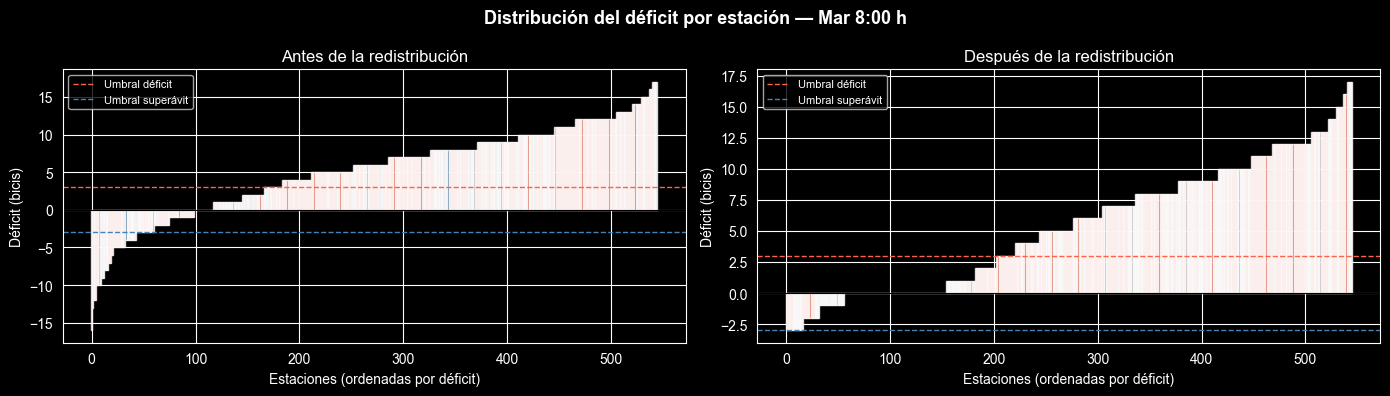

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, df, title in [
    (axes[0], snap,       'Antes de la redistribución'),
    (axes[1], snap_after, 'Después de la redistribución'),
]:
    colors = df['deficit'].apply(
        lambda d: 'tomato' if d > MIN_BIKES else ('steelblue' if d < -MIN_BIKES else 'lightgrey')
    )
    ax.bar(range(len(df)), df['deficit'].sort_values(), color=colors.values, alpha=0.8, width=1.0)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axhline( MIN_BIKES, color='tomato',    linestyle='--', linewidth=1.0, label='Umbral déficit')
    ax.axhline(-MIN_BIKES, color='steelblue', linestyle='--', linewidth=1.0, label='Umbral superávit')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Estaciones (ordenadas por déficit)')
    ax.set_ylabel('Déficit (bicis)')
    ax.legend(fontsize=8)

plt.suptitle('Distribución del déficit por estación — Mar 8:00 h', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 4.3 Mapa interactivo de rutas

In [44]:
TRUCK_COLORS = ['blue', 'red', 'green', 'purple', 'orange']

m2 = folium.Map(location=[41.3900, 2.1540], zoom_start=13, tiles='CartoDB positron')

# Depósito
folium.Marker(
    location=[DEPOT_LAT, DEPOT_LON],
    icon=folium.Icon(color='black', icon='home', prefix='fa'),
    tooltip=f"<b>{DEPOT_NAME}</b>",
).add_to(m2)

for r in routes:
    color  = TRUCK_COLORS[(r['truck_id'] - 1) % len(TRUCK_COLORS)]
    coords = [(DEPOT_LAT, DEPOT_LON)]

    for i, stop in enumerate(r['stops']):
        coords.append((stop['lat'], stop['lon']))
        icon_color = 'red' if stop['action'] == 'entrega' else 'blue'
        icon_sym   = 'arrow-down' if stop['action'] == 'entrega' else 'arrow-up'
        folium.CircleMarker(
            location=[stop['lat'], stop['lon']],
            radius=7,
            color=color,
            fill=True,
            fill_color=icon_color,
            fill_opacity=0.8,
            tooltip=(
                f"<b>Camión {r['truck_id']} — Parada {i+1}</b><br>"
                f"{stop['name']}<br>"
                f"Acción: <b>{stop['action']}</b><br>"
                f"Bicis: {stop['bikes']}<br>"
                f"Carga tras parada: {stop['load_after']}"
            ),
        ).add_to(m2)

    coords.append((DEPOT_LAT, DEPOT_LON))
    folium.PolyLine(
        locations=coords,
        color=color,
        weight=2.5,
        opacity=0.75,
        tooltip=f"Camión {r['truck_id']} — {r['km_total']} km",
    ).add_to(m2)

# Leyenda
legend = '''
<div style="position:fixed;bottom:30px;left:30px;z-index:1000;
     background:white;padding:10px;border-radius:8px;
     border:1px solid #ccc;font-size:12px;">
  <b>Acciones</b><br>
  <span style="color:red">●</span> Entrega de bicis<br>
  <span style="color:steelblue">●</span> Recogida de bicis<br>
  <span style="color:black">⌂</span> Depósito
</div>
'''
m2.get_root().html.add_child(folium.Element(legend))
m2


### 4.4 Detalle de rutas por camión

In [45]:
for r in routes:
    stops_df = pd.DataFrame(r['stops'])
    if stops_df.empty:
        print(f"\nCamión {r['truck_id']}: sin paradas.\n")
        continue

    print(f"\n{'═'*65}")
    print(f"  Camión {r['truck_id']}  |  {len(r['stops'])} paradas  |  "
          f"{r['km_total']:.1f} km  |  {r['bikes_moved']} bicis entregadas")
    print(f"{'═'*65}")
    display(
        stops_df[['name', 'action', 'bikes', 'load_after', 'km_step']]
        .rename(columns={
            'name':       'Estación',
            'action':     'Acción',
            'bikes':      'Bicis',
            'load_after': 'Carga tras parada',
            'km_step':    'km paso',
        })
        .style.map(
            lambda v: 'color: tomato' if v == 'entrega' else 'color: steelblue',
            subset=['Acción']
        )
        .format({'km paso': '{:.3f}'})
        .hide(axis='index')
    )



═════════════════════════════════════════════════════════════════
  Camión 1  |  20 paradas  |  16.3 km  |  65 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
"GRAN VIA DE LES CORTS CATALANES, 368",recogida,6,6,0.750
"C/RADI,10/GRAN VIA DE LES CORTS CATALA",recogida,5,11,1.680
"C/ DE L'ENERGIA, 2 / ALTS FORNS",recogida,5,16,0.709
PL. TERESA DE CLARAMUNT/C/ DELS FERROCA,entrega,9,7,0.679
JARDINS DE CAN FERRERO/PG.DE LA ZONA FR,recogida,9,16,0.687
"C/ MARBRE, 2",entrega,4,12,0.699
"PG. ZONA FRANCA, 9",recogida,4,16,1.142
"AV. ESTADI, 12",entrega,7,9,1.575
"C/ PALAUDÀRIES, 2",recogida,7,16,2.352
"PL. JEAN GENET, 1",entrega,4,12,0.262



═════════════════════════════════════════════════════════════════
  Camión 2  |  20 paradas  |  18.8 km  |  54 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
"PL. CATALUNYA, 10-11 (PG. DE GRÀCIA)",recogida,5,5,2.639
"GRAN VIA DE LES CORTS CATALANES, 632",recogida,4,9,0.209
PG. DE COLOM /VIA LAIETANA,recogida,4,13,1.521
PL. PAU VILA (D),recogida,4,17,0.361
"AV. MARQUÉS DE L'ARGENTERA,13",entrega,5,12,0.413
"C/ DEL DR. AIGUADER, 72 / PG. SALVAT",recogida,8,20,0.552
"PG. MARÍTIM DE LA BARCELONETA, 6",entrega,5,15,0.481
"AV. MARQUÉS DE L'ARGENTERA, 15",entrega,6,9,0.852
"C/ VILLENA, 1",recogida,10,19,0.726
"C/ RAMON TRIAS FARGAS, 21",entrega,15,4,0.234



═════════════════════════════════════════════════════════════════
  Camión 3  |  20 paradas  |  24.5 km  |  57 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
C/ NOVA BOCANA,recogida,8,8,2.999
MOLL ORIENTAL,recogida,8,16,0.090
"PL. SANT MIQUEL, 4",entrega,7,9,1.628
"C/ PONTEVEDRA, 58B | C/ JUDICI",recogida,4,13,1.240
"C/ SANCHO DE ÁVILA, 60-64",recogida,9,22,2.435
"AV. MERIDIANA, 71",entrega,5,17,0.417
"C/ RIBES, 77",entrega,9,8,0.265
"C/ BOLÍVIA, 76",recogida,7,15,0.681
"GRAN VIA DE LES CORTS CATALANES, 902",entrega,4,11,0.517
"C/ SANCHO DE ÁVILA, 104 - C/ BADAJOZ",recogida,13,24,0.794



═════════════════════════════════════════════════════════════════
  Camión 4  |  20 paradas  |  36.0 km  |  77 bicis entregadas
═════════════════════════════════════════════════════════════════


Estación,Acción,Bicis,Carga tras parada,km paso
"C/ CRISTOBAL DE MOURA, 84",recogida,5,5,6.556
"C/ CRISTÓBAL DE MOURA, 163 (xamfrà)",recogida,5,10,0.409
"GRAN VIA DE LES CORTS CATALANES, 1062",recogida,5,15,0.632
"RAMBLA DE GUIPÚSCOA, 43/FLUVIA",entrega,7,8,0.530
"AV. DIAGONAL, 26",recogida,5,13,1.777
"RAMBLA DE PRIM, 19",recogida,10,23,0.180
"RAMBLA DE GUIPÚSCOA, 158/ CA N'OLIVA",entrega,6,17,1.607
"RAMBLA DE GUIPÚSCOA, 103 / CANTÀBRIA",entrega,6,11,0.477
"C/ LLULL, 465",recogida,8,19,1.539
"C/ CANTÀBRIA, 55",entrega,7,12,1.933



Camión 5: sin paradas.



### 4.5 Resumen ejecutivo del modelo BRP

In [46]:
mejora_criticas = (before['n_critical'] - after['n_critical']) / before['n_critical'] * 100
mejora_deficit  = (before['total_deficit'] - after['total_deficit']) / before['total_deficit'] * 100
mejora_rmse     = (before['rmse_deficit'] - after['rmse_deficit']) / before['rmse_deficit'] * 100

print('=' * 60)
print('RESUMEN EJECUTIVO — Modelo BRP (Greedy Nearest-Neighbor)')
print('=' * 60)
print(f"Escenario          : Martes 08:00 h (hora punta)")
print(f"Flota              : {N_TRUCKS} camiones × {TRUCK_CAP} bicis")
print(f"Paradas máx./ruta  : {MAX_STOPS}")
print()
print(f"Estaciones críticas reducidas : {before['n_critical']} → {after['n_critical']}  ({mejora_criticas:+.1f}%)")
print(f"Déficit total reducido        : {before['total_deficit']} → {after['total_deficit']} bicis  ({mejora_deficit:+.1f}%)")
print(f"RMSE déficit reducido         : {before['rmse_deficit']} → {after['rmse_deficit']}  ({mejora_rmse:+.1f}%)")
print()
print(f"Bicicletas redistribuidas     : {total_bikes}")
print(f"Kilómetros totales recorridos : {total_km:.1f} km")
print(f"Eficiencia (km/bici)          : {total_km/max(total_bikes,1):.2f} km/bici")
print('=' * 60)
print()
print('Limitaciones del modelo:')
print('  · Heurística greedy: no garantiza solución óptima global.')
print('  · Distancias euclídeas (Haversine), sin tráfico ni topografía.')
print('  · Escenario estático: se asume que las bicicletas no se mueven')
print('    durante la redistribución.')
print()
print('Posibles mejoras:')
print('  · Integrar predicción LSTM/XGBoost para anticipar demanda.')
print('  · Metaheurísticas (Simulated Annealing, Algoritmo Genético).')
print('  · Enrutamiento con OSRM/Google Maps para distancias reales.')


RESUMEN EJECUTIVO — Modelo BRP (Greedy Nearest-Neighbor)
Escenario          : Martes 08:00 h (hora punta)
Flota              : 5 camiones × 30 bicis
Paradas máx./ruta  : 20

Estaciones críticas reducidas : 404 → 324  (+19.8%)
Déficit total reducido        : 3127 → 2874 bicis  (+8.1%)
RMSE déficit reducido         : 7.84 → 7.31  (+6.8%)

Bicicletas redistribuidas     : 253
Kilómetros totales recorridos : 95.7 km
Eficiencia (km/bici)          : 0.38 km/bici

Limitaciones del modelo:
  · Heurística greedy: no garantiza solución óptima global.
  · Distancias euclídeas (Haversine), sin tráfico ni topografía.
  · Escenario estático: se asume que las bicicletas no se mueven
    durante la redistribución.

Posibles mejoras:
  · Integrar predicción LSTM/XGBoost para anticipar demanda.
  · Metaheurísticas (Simulated Annealing, Algoritmo Genético).
  · Enrutamiento con OSRM/Google Maps para distancias reales.
